<a href="https://colab.research.google.com/github/islamsamian22-ship-it/Python-prohects/blob/main/Twitter_sentiment_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mounted at /content/drive
Raw shape: (74682, 4)
sentiment
Negative      22542
Positive      20832
Neutral       18318
Irrelevant    12990
Name: count, dtype: int64
Shape after cleaning nulls/duplicates: (69769, 4)
Shape after text cleaning: (69611, 5)
Classes: {0: 'Irrelevant', 1: 'Negative', 2: 'Neutral', 3: 'Positive'}

Training Logistic Regression...
Logistic Regression accuracy: 0.7362
              precision    recall  f1-score   support

  Irrelevant       0.73      0.59      0.65      2451
    Negative       0.74      0.84      0.79      4239
     Neutral       0.74      0.69      0.71      3412
    Positive       0.73      0.76      0.74      3821

    accuracy                           0.74     13923
   macro avg       0.74      0.72      0.72     13923
weighted avg       0.74      0.74      0.73     13923


Training Random Forest...
Random Forest accuracy: 0.7938
              precision    recall  f1-score   support

  Irrelevant       0.91      0.61      0.73      2451
    N

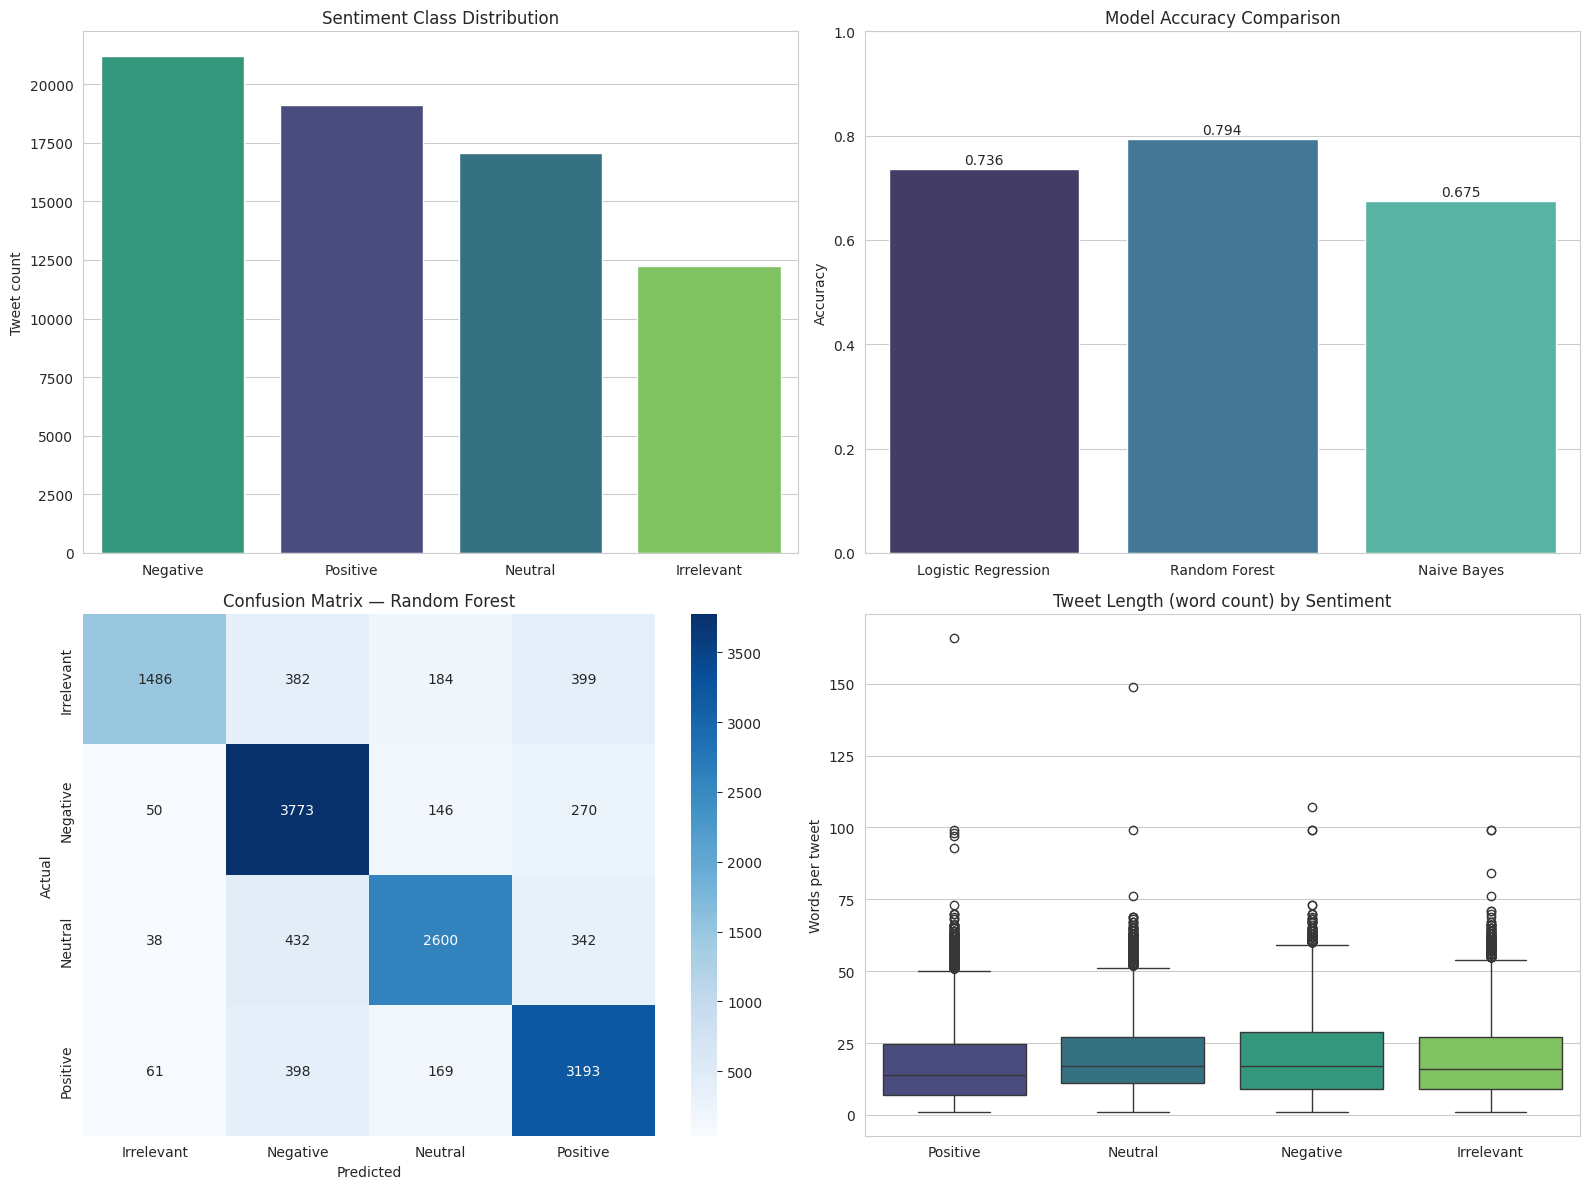

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
import joblib
import re
from google.colab import drive
drive.mount('/content/drive', force_remount=True)


sns.set_style("whitegrid")

df = pd.read_csv(
    "/content/drive/MyDrive/Python /twitter_training.csv",
    header=None,
    names=["tweet_id", "entity", "sentiment", "text"],
)


print(f"Raw shape: {df.shape}")
print(df["sentiment"].value_counts())

df = df.dropna(subset=["text"])

df = df.drop_duplicates(subset=["text", "sentiment"])

print(f"Shape after cleaning nulls/duplicates: {df.shape}")


def clean_text(text: str) -> str:
    """
    Normalize raw tweet text before vectorization:
    - lowercase everything (so 'Good' and 'good' are treated the same)
    - strip URLs (they carry no sentiment signal as text)
    - strip @mentions and #hashtag symbols (keep the hashtag word itself)
    - remove punctuation and digits
    - collapse extra whitespace
    """
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)          # URLs
    text = re.sub(r"@\w+", " " , text)                       # mentions
    text = re.sub(r"#", " ", text)                          # keep hashtag word, drop symbol
    text = re.sub(r"[^a-z\s]", " ", text)                   # punctuation/digits
    text = re.sub(r"\s+", " ", text).strip()                # extra whitespace
    return text
df["clean_text"] = df["text"].apply(clean_text)

df = df[df["clean_text"].str.len() > 0]
print(f"Shape after text cleaning: {df.shape}")

label_encoder = LabelEncoder()
df["sentiment"] = df["sentiment"].astype(str)
df["label"] = label_encoder.fit_transform(df["sentiment"])
class_names = label_encoder.classes_
print("Classes:", dict(enumerate(class_names)))

X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"],
    df["label"],
    test_size=0.2,
    random_state=42,
    stratify=df["label"],)

vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    stop_words=list(ENGLISH_STOP_WORDS),
    min_df=3,)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)


models = {
    "Logistic Regression": LogisticRegression(max_iter=500),
    "Random Forest": RandomForestClassifier(
        n_estimators=150, min_samples_leaf=2, n_jobs=1, random_state=42
    ),
    "Naive Bayes": MultinomialNB(),
}

results = {}
predictions = {}

for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    predictions[name] = y_pred
    print(f"{name} accuracy: {acc:.4f}")
    print(classification_report(y_test, y_pred, target_names=class_names))


best_model_name = max(results, key=results.get)
best_model = models[best_model_name]
best_pred = predictions[best_model_name]
print(f"\nBest model: {best_model_name} ({results[best_model_name]:.4f} accuracy)")


fig, axes = plt.subplots(2, 2, figsize=(16, 12))

sns.countplot(
    data=df, x="sentiment", order=df["sentiment"].value_counts().index,
    ax=axes[0, 0], hue="sentiment", palette="viridis", legend=False,
)
axes[0, 0].set_title("Sentiment Class Distribution")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Tweet count")

sns.barplot(
    x=list(results.keys()), y=list(results.values()),
    hue=list(results.keys()), palette="mako", legend=False, ax=axes[0, 1],
)
axes[0, 1].set_title("Model Accuracy Comparison")
axes[0, 1].set_ylabel("Accuracy")
axes[0, 1].set_ylim(0, 1)
for i, v in enumerate(results.values()):
    axes[0, 1].text(i, v + 0.01, f"{v:.3f}", ha="center")


cm = confusion_matrix(y_test, best_pred)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names, ax=axes[1, 0],
)
axes[1, 0].set_title(f"Confusion Matrix — {best_model_name}")
axes[1, 0].set_xlabel("Predicted")
axes[1, 0].set_ylabel("Actual")

df["text_length"] = df["clean_text"].str.split().apply(len)
sns.boxplot(
    data=df, x="sentiment", y="text_length",
    hue="sentiment", palette="viridis", legend=False, ax=axes[1, 1],
)
axes[1, 1].set_title("Tweet Length (word count) by Sentiment")
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("Words per tweet")

plt.tight_layout()
plt.savefig("sentiment_analysis_results.png", dpi=150)
print("\nSaved visualization to sentiment_analysis_results.png")

joblib.dump(best_model, "best_sentiment_model.joblib")
joblib.dump(vectorizer, "tfidf_vectorizer.joblib")
joblib.dump(label_encoder, "label_encoder.joblib")
print("Saved model, vectorizer, and label encoder to disk.")

def predict_sentiment(text: str) -> str:
    """
    Run the trained pipeline on a single new piece of text.
    """
    cleaned = clean_text(text)
    vec = vectorizer.transform([cleaned])
    pred_label = best_model.predict(vec)[0]
    return label_encoder.inverse_transform([pred_label])[0]


if __name__ == "__main__":
    sample_tweets = [
        "I absolutely love this game, best purchase ever!",
        "This is the worst customer service I've ever experienced.",
        "The event starts at 6pm tomorrow.",
    ]
    print("\nSample predictions:")
    for t in sample_tweets:
        print(f"  '{t}' -> {predict_sentiment(t)}")

In [ ]:
import os

# List the contents of your Google Drive's MyDrive folder
print(os.listdir('/content/drive/MyDrive'))

import subprocess
result = subprocess.run(['find', '/content/drive/MyDrive', '-iname', '*twitter*'], capture_output=True, text=True)
print(result.stdout)


['Colab Notebooks', 'ES PML 2504', 'Python ', 'train.csv', 'Physics Mock QP.docx', '1 Mixture- a substance made when two or more are combined,not chemically bonded.gdoc', '3746_0115876_ORIGSIZE (1).jpg', '3746_0115876_ORIGSIZE.jpg', 'AQA_Biology_Infection and Response KnowIT_GCSE - QUESTIONS-1.docx', 'Itinerary 1028444-1 (1).pdf', 'Itinerary 1028444-1.pdf', 'Abbey DLD International Application Form.pdf', 'Offer Letter ISLAM Samian (1).pdf', 'Contact Form (1).pdf', 'Contact Form.pdf', 'Offer Letter ISLAM Samian.pdf', 'Biomes.pptx', '8464-B-2H-QP-CombinedScienceTrilogy-G-15Jun22-AM.pdf', '8464-C-2H-QP-CombinedScienceTrilogy-G-20Jun22-AM.pdf', '8464-P-2H-QP-CombinedScienceTrilogy-G-23Jun22-AM.pdf', 'Personal statement.gdoc', 'Copy of Personal statement.gdoc', 'Master Copy of Personal statement (1).docx', 'Classroom', 'Samian Islam Resume.docx', 'Copy of Biomes.pptx', 'AQA_Biology_Ecology_KnowIT_GCSE_Questions (1).docx', '1ma1-1f-que-20220521 (1).pdf', '1ma1-2f-que-20220608.pdf', '1ma1-1f-